# Repetition code memory: Stim + PyMatching + sinter

Fixed number of rounds for every distance, log-spaced physical error rates,
and sinter for sampling and error bars.

**Noise model:** `p` is used for (a) depolarizing noise on data qubits before each round
(only the X and Y parts flip a data qubit here, so the effective data bit-flip rate is about 2p/3),
(b) measurement flips and (c) reset flips.

In [ ]:
!pip install -q stim pymatching sinter numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching
import sinter

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| sinter", sinter.__version__)

stim 1.16.0 | pymatching 2.4.0 | sinter 1.16.0


## 1. Look at the circuit (data noise only, for reading)

In [ ]:
circuit = stim.Circuit.generated(
    "repetition_code:memory",
    distance=3,
    rounds=9,
    before_round_data_depolarization=0.05,
)
print(circuit)

R 0 1 2 3 4
TICK
DEPOLARIZE1(0.05) 0 2 4
CX 0 1 2 3
TICK
CX 2 1 4 3
TICK
MR 1 3
DETECTOR(1, 0) rec[-2]
DETECTOR(3, 0) rec[-1]
REPEAT 8 {
    TICK
    DEPOLARIZE1(0.05) 0 2 4
    CX 0 1 2 3
    TICK
    CX 2 1 4 3
    TICK
    MR 1 3
    SHIFT_COORDS(0, 1)
    DETECTOR(1, 0) rec[-2] rec[-4]
    DETECTOR(3, 0) rec[-1] rec[-3]
}
M 0 2 4
DETECTOR(1, 1) rec[-2] rec[-3] rec[-5]
DETECTOR(3, 1) rec[-1] rec[-2] rec[-4]
OBSERVABLE_INCLUDE(0) rec[-1]


## 2. Single-point function (your original logic, with fixed rounds and a seed)

In [ ]:
def logical_error_rate(distance, p, rounds=10, shots=100_000, seed=None):
    circuit = stim.Circuit.generated(
        "repetition_code:memory",
        distance=distance,
        rounds=rounds,
        before_round_data_depolarization=p,
        before_measure_flip_probability=p,
        after_reset_flip_probability=p,
    )
    dem = circuit.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)

    sampler = circuit.compile_detector_sampler(seed=seed)
    detections, observables = sampler.sample(shots, separate_observables=True)

    predictions = matching.decode_batch(detections)
    errors = np.sum(np.any(predictions != observables, axis=1))
    return errors / shots

# Sanity checks
print("p = 0    ->", logical_error_rate(3, 0.0, shots=10_000))      # must be 0
print("p = 0.05 ->", logical_error_rate(3, 0.05, seed=1))

p = 0    -> 0.0
p = 0.05 -> 0.1273


## 3. Full sweep with sinter (fixed rounds, enough shots, proper error bars)

In [ ]:
DISTANCES = [3, 5, 7]
ROUNDS = 10                                              # same for every distance
PS = np.logspace(np.log10(0.005), np.log10(0.3), 18)     # 0.5% to 30%, log spaced

def make_tasks():
    for d in DISTANCES:
        for p in PS:
            c = stim.Circuit.generated(
                "repetition_code:memory",
                distance=d,
                rounds=ROUNDS,
                before_round_data_depolarization=p,
                before_measure_flip_probability=p,
                after_reset_flip_probability=p,
            )
            yield sinter.Task(circuit=c, json_metadata={"d": d, "p": float(p)})

stats = sinter.collect(
    num_workers=os.cpu_count() or 1,
    tasks=make_tasks(),
    decoders=["pymatching"],
    max_shots=2_000_000,     # upper limit per point
    max_errors=400,          # stop a point once 400 failures are seen
    print_progress=True,
)

## 4. Plot: per shot and per round

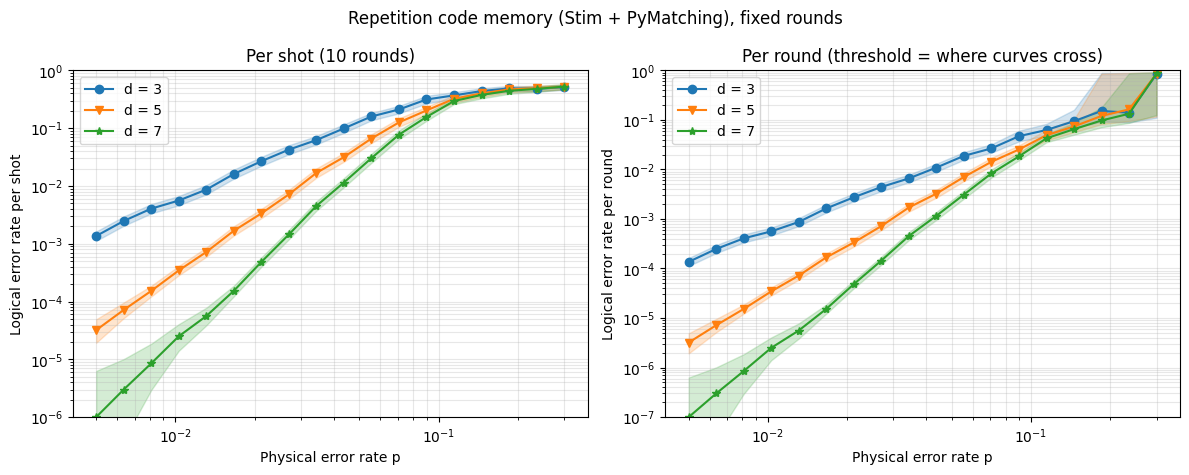

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, per_round in zip(axs, [False, True]):
    extra = dict(failure_units_per_shot_func=lambda s: ROUNDS,
                 failure_values_func=lambda s: 1) if per_round else {}
    sinter.plot_error_rate(
        ax=ax,
        stats=stats,
        group_func=lambda s: f"d = {s.json_metadata['d']}",
        x_func=lambda s: s.json_metadata["p"],
        **extra,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Physical error rate p")
    ax.set_ylabel("Logical error rate per round" if per_round
                  else "Logical error rate per shot")
    ax.set_title("Per round (threshold = where curves cross)" if per_round
                 else f"Per shot ({ROUNDS} rounds)")
    ax.grid(which="both", alpha=0.3)
    ax.legend()

axs[0].set_ylim(1e-6, 1)
axs[1].set_ylim(1e-7, 1)
fig.suptitle("Repetition code memory (Stim + PyMatching), fixed rounds")
fig.tight_layout()
fig.savefig("repetition_code_final.png", dpi=200)
plt.show()

## 5. Check the numbers (failures per point)

In [ ]:
for s in sorted(stats, key=lambda s: (s.json_metadata["d"], s.json_metadata["p"])):
    rate = s.errors / s.shots
    print(f"d={s.json_metadata['d']}  p={s.json_metadata['p']:.4f}  "
          f"shots={s.shots:>9,}  failures={s.errors:>4}  rate={rate:.2e}")

d=3  p=0.0050  shots=  294,161  failures= 400  rate=1.36e-03
d=3  p=0.0064  shots=  162,065  failures= 401  rate=2.47e-03
d=3  p=0.0081  shots=   99,601  failures= 403  rate=4.05e-03
d=3  p=0.0103  shots=   71,953  failures= 402  rate=5.59e-03
d=3  p=0.0131  shots=   46,353  failures= 400  rate=8.63e-03
d=3  p=0.0167  shots=   25,873  failures= 416  rate=1.61e-02
d=3  p=0.0212  shots=   15,633  failures= 418  rate=2.67e-02
d=3  p=0.0270  shots=    9,489  failures= 403  rate=4.25e-02
d=3  p=0.0343  shots=    7,441  failures= 462  rate=6.21e-02
d=3  p=0.0437  shots=    4,369  failures= 432  rate=9.89e-02
d=3  p=0.0556  shots=    3,345  failures= 532  rate=1.59e-01
d=3  p=0.0707  shots=    2,321  failures= 488  rate=2.10e-01
d=3  p=0.0900  shots=    1,297  failures= 406  rate=3.13e-01
d=3  p=0.1145  shots=    1,297  failures= 478  rate=3.69e-01
d=3  p=0.1457  shots=    1,297  failures= 568  rate=4.38e-01
d=3  p=0.1853  shots=    1,297  failures= 631  rate=4.87e-01
d=3  p=0.2358  shots=   